# Visualizing $\log(z)$ on the Complex Plane

For the principal branch,
$$
\log(z)=\ln|z| + i\operatorname{Arg}(z),\quad \operatorname{Arg}(z)\in(-\pi,\pi].
$$
This visualization shows:
- A domain-coloring style map of $\log(z)$.
- Heatmaps of
$$
\Re(\log z)=\ln|z|
$$
and
$$
\Im(\log z)=\operatorname{Arg}(z).
$$

Note: $z=0$ is singular, and the principal branch cut is along the negative real axis.

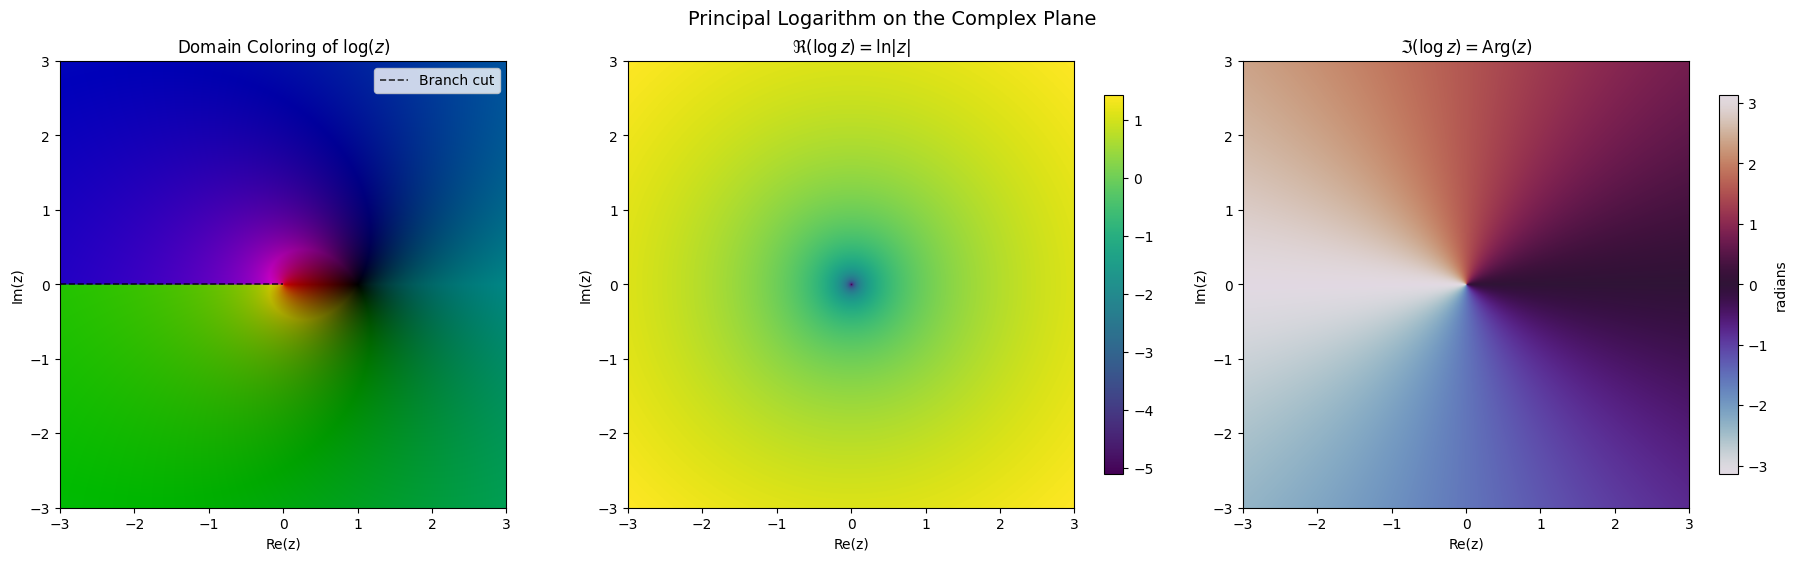

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb

# Grid in the z-plane
n = 700
x = np.linspace(-3, 3, n)
y = np.linspace(-3, 3, n)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

# Magnitude and principal argument
R = np.abs(Z)
Theta = np.angle(Z)  # principal argument in (-pi, pi]
mask0 = R < 1e-6

# Principal branch of log(z): log(z) = ln|z| + i Arg(z)
# Keep origin masked to avoid singularity artifacts.
with np.errstate(divide="ignore", invalid="ignore"):
    ReLog = np.log(R)
ReLog = np.where(mask0, np.nan, ReLog)
ImLog = np.where(mask0, np.nan, Theta)

# Domain-coloring style image for log(z)
# Hue encodes arg(log z), brightness encodes |log z|.
W = ReLog + 1j * ImLog
argW = np.angle(W)
magW = np.abs(W)

hue = (argW + np.pi) / (2 * np.pi)
value = 1 - 1 / (1 + np.nan_to_num(magW, nan=0.0))
sat = np.ones_like(hue)

rgb = hsv_to_rgb(np.dstack([np.nan_to_num(hue, nan=0.0), sat, value]))
rgb[mask0] = 0.0  # color the singular point neighborhood black

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

# 1) Domain coloring of log(z)
axes[0].imshow(
    rgb,
    extent=[x.min(), x.max(), y.min(), y.max()],
    origin="lower",
    aspect="equal",
)
axes[0].set_title(r"Domain Coloring of $\log(z)$")
axes[0].set_xlabel("Re(z)")
axes[0].set_ylabel("Im(z)")
axes[0].plot([-3, 0], [0, 0], "k--", lw=1.2, alpha=0.8, label="Branch cut")
axes[0].legend(loc="upper right")

# 2) Re(log z) = ln|z|
im1 = axes[1].imshow(
    ReLog,
    extent=[x.min(), x.max(), y.min(), y.max()],
    origin="lower",
    aspect="equal",
    cmap="viridis",
)
axes[1].set_title(r"$\Re(\log z)=\ln|z|$")
axes[1].set_xlabel("Re(z)")
axes[1].set_ylabel("Im(z)")
plt.colorbar(im1, ax=axes[1], shrink=0.85)

# 3) Im(log z) = Arg(z)
im2 = axes[2].imshow(
    ImLog,
    extent=[x.min(), x.max(), y.min(), y.max()],
    origin="lower",
    aspect="equal",
    cmap="twilight",
    vmin=-np.pi,
    vmax=np.pi,
)
axes[2].set_title(r"$\Im(\log z)=\operatorname{Arg}(z)$")
axes[2].set_xlabel("Re(z)")
axes[2].set_ylabel("Im(z)")
plt.colorbar(im2, ax=axes[2], shrink=0.85, label="radians")

plt.suptitle("Principal Logarithm on the Complex Plane", fontsize=14)
plt.show()

## Why `log(z)` Looks Like a Spiral Staircase

Write `z = r e^{i\theta}`. Then

$$
\log(z) = \ln r + i\theta.
$$

But angle is multi-valued: `\theta + 2\pi k` for any integer `k`. So each branch is

$$
\log_k(z) = \ln r + i(\theta + 2\pi k), \quad k\in\mathbb{Z}.
$$

Geometrically, if you use height = `Im(log z)`, each branch is one level of a spiral staircase, shifted by `2\pi`.

For the **principal branch**, we restrict `\theta \in (-\pi, \pi]`, so you only keep one sheet with a jump across the negative real axis (the branch cut).

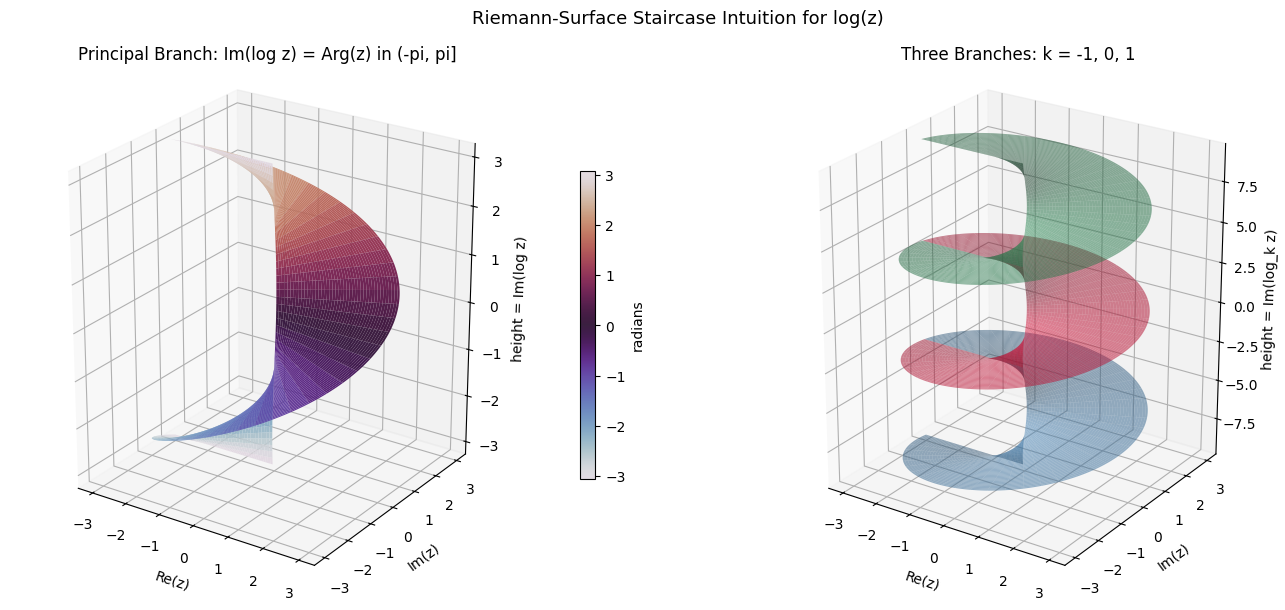

In [2]:
# 3D staircase view of log(z): principal sheet and nearby sheets
n = 220
r = np.linspace(0.05, 3.0, n)
theta = np.linspace(-np.pi, np.pi, n)
R, Theta = np.meshgrid(r, theta)

X = R * np.cos(Theta)
Y = R * np.sin(Theta)
Z_principal = Theta  # Im(log z) on principal branch

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# Principal branch: one sheet with branch-cut jump at +/- pi
surf1 = ax1.plot_surface(X, Y, Z_principal, cmap='twilight', linewidth=0, antialiased=True, alpha=0.95)
ax1.set_title('Principal Branch: Im(log z) = Arg(z) in (-pi, pi]')
ax1.set_xlabel('Re(z)')
ax1.set_ylabel('Im(z)')
ax1.set_zlabel('height = Im(log z)')
fig.colorbar(surf1, ax=ax1, shrink=0.6, pad=0.08, label='radians')

# Nearby branches to show staircase structure
for k, c in [(-1, 'steelblue'), (0, 'crimson'), (1, 'seagreen')]:
    Zk = Theta + 2*np.pi*k
    ax2.plot_surface(X, Y, Zk, color=c, linewidth=0, alpha=0.52)

ax2.set_title('Three Branches: k = -1, 0, 1')
ax2.set_xlabel('Re(z)')
ax2.set_ylabel('Im(z)')
ax2.set_zlabel('height = Im(log_k z)')

# Keep vertical scale comparable and easy to read
for ax in (ax1, ax2):
    ax.set_box_aspect((1, 1, 1.2))
    ax.view_init(elev=24, azim=-56)

plt.suptitle('Riemann-Surface Staircase Intuition for log(z)', fontsize=13)
plt.tight_layout()
plt.show()

## Interactive 3D Staircase — rotate with mouse drag

In [3]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

n = 220
r = np.linspace(0.05, 3.0, n)
theta = np.linspace(-np.pi, np.pi, n)
R, Theta = np.meshgrid(r, theta)

X = R * np.cos(Theta)
Y = R * np.sin(Theta)
ReLog = np.log(R)   # Re(log z) = ln|z|  — single-valued, same for all k

branch_colors = {-1: 'steelblue', 0: 'crimson', 1: 'seagreen'}
branch_labels = {-1: 'k=-1: (-3π, -π]', 0: 'k=0: (-π, π]', 1: 'k=1: (π, 3π]'}

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "surface"}, {"type": "surface"}]],
    subplot_titles=[
        "Im(log_k z) = Arg(z) + 2πk  [multi-valued — 3 branches]",
        "Re(log z) = ln|z|  [single-valued — same for all k]",
    ],
)

# Left: three imaginary-part branches
for k, color in branch_colors.items():
    Zk = Theta + 2 * np.pi * k
    fig.add_trace(
        go.Surface(
            x=X, y=Y, z=Zk,
            colorscale=[[0, color], [1, color]],
            showscale=False,
            opacity=0.6,
            name=branch_labels[k],
            showlegend=True,
            hovertemplate='Re(z)=%{x:.2f}<br>Im(z)=%{y:.2f}<br>Im(log_k z)=%{z:.2f}'
                          '<extra>' + branch_labels[k] + '</extra>',
        ),
        row=1, col=1,
    )

# Right: single real part surface
fig.add_trace(
    go.Surface(
        x=X, y=Y, z=ReLog,
        colorscale='Viridis',
        showscale=True,
        opacity=0.9,
        colorbar=dict(title='ln|z|', x=1.02, len=0.7),
        name='Re(log z) = ln|z|',
        showlegend=True,
        hovertemplate='Re(z)=%{x:.2f}<br>Im(z)=%{y:.2f}<br>Re(log z)=ln|z|=%{z:.2f}<extra>Re(log z)</extra>',
    ),
    row=1, col=2,
)

camera = dict(eye=dict(x=1.4, y=-1.4, z=0.8))
fig.update_layout(
    title='Both Parts of log(z): Im is multi-valued, Re is single-valued',
    scene=dict(
        xaxis_title='Re(z)', yaxis_title='Im(z)', zaxis_title='Im(log_k z)',
        aspectratio=dict(x=1, y=1, z=1.2), camera=camera,
    ),
    scene2=dict(
        xaxis_title='Re(z)', yaxis_title='Im(z)', zaxis_title='Re(log z) = ln|z|',
        aspectratio=dict(x=1, y=1, z=1.2), camera=camera,
    ),
    legend=dict(x=0.01, y=0.95),
    width=1200,
    height=620,
)
fig.show()


## Taylor Series on a Circle Becomes a Fourier Series

If $f$ is holomorphic on a disk $|z| < R$, then it has a Taylor series

$$
f(z) = \sum_{n=0}^{\infty} a_n z^n.
$$

Now restrict to a circle of radius $r < R$ by writing

$$
z = r e^{i\theta}.
$$

Substituting into the Taylor series gives

$$
f(r e^{i\theta}) = \sum_{n=0}^{\infty} a_n r^n e^{i n \theta}.
$$

This is a Fourier series in $\theta$, with Fourier coefficients

$$
c_n(r) = a_n r^n \quad \text{for } n \ge 0,
$$

and no negative-frequency terms. So for a holomorphic function on a disk, the restriction of $f$ to any circle $|z| = r$ has a Fourier series containing only nonnegative modes.


If instead $f$ is holomorphic on an annulus, then it has a Laurent series

$$
f(z) = \sum_{n=-\infty}^{\infty} a_n z^n,
$$

and on $z = r e^{i\theta}$ this becomes

$$
f(r e^{i\theta}) = \sum_{n=-\infty}^{\infty} a_n r^n e^{i n \theta},
$$

which is the full two-sided Fourier series.

## What an Annulus Is

An **annulus** is the ring-shaped region between two circles. Centered at the origin, it is

$$
A = \{z \in \mathbb{C} : r_1 < |z| < r_2\}, \qquad 0 < r_1 < r_2.
$$

So it is like a disk with a circular hole removed.


Why this matters for complex analysis: on a disk, a holomorphic function expands in a Taylor series with only nonnegative powers of $z$. On an annulus, the hole allows terms like $z^{-1}, z^{-2}, \dots$, so the natural expansion is a Laurent series

$$
f(z) = \sum_{n=-\infty}^{\infty} a_n z^n.
$$

If you then write $z = r e^{i\theta}$ with $r_1 < r < r_2$, this becomes

$$
f(r e^{i\theta}) = \sum_{n=-\infty}^{\infty} a_n r^n e^{i n \theta},
$$

which is a full Fourier series with both positive and negative modes.


A standard example is $f(z)=z+\frac{1}{z}$, which is holomorphic on any annulus that avoids $z=0$, but not on a full disk containing the origin.

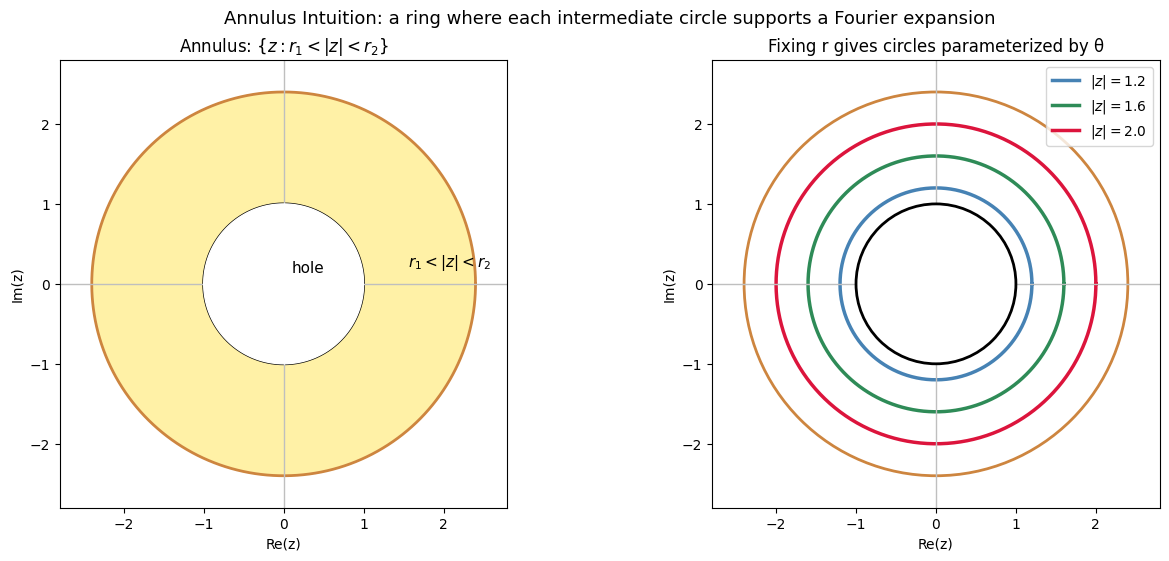

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

theta = np.linspace(0, 2 * np.pi, 600)
r_inner = 1.0
r_outer = 2.4

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

# Left: the annulus itself
ax = axes[0]
ax.fill(r_outer * np.cos(theta), r_outer * np.sin(theta), color='gold', alpha=0.35, label='outer disk')
ax.fill(r_inner * np.cos(theta), r_inner * np.sin(theta), color='white', zorder=3, label='removed inner disk')
ax.plot(r_outer * np.cos(theta), r_outer * np.sin(theta), color='peru', lw=2)
ax.plot(r_inner * np.cos(theta), r_inner * np.sin(theta), color='black', lw=2)
ax.axhline(0, color='0.75', lw=1)
ax.axvline(0, color='0.75', lw=1)
ax.set_aspect('equal')
ax.set_xlim(-2.8, 2.8)
ax.set_ylim(-2.8, 2.8)
ax.set_title(r'Annulus: $\{z : r_1 < |z| < r_2\}$')
ax.set_xlabel('Re(z)')
ax.set_ylabel('Im(z)')
ax.text(0.1, 0.15, 'hole', fontsize=11)
ax.text(1.55, 0.22, r'$r_1 < |z| < r_2$', fontsize=11)

# Right: circles inside the annulus
ax = axes[1]
sample_radii = [1.2, 1.6, 2.0]
colors = ['steelblue', 'seagreen', 'crimson']
for radius, color in zip(sample_radii, colors):
    ax.plot(radius * np.cos(theta), radius * np.sin(theta), color=color, lw=2.5, label=fr'$|z|={radius}$')

ax.add_patch(Circle((0, 0), r_inner, facecolor='white', edgecolor='black', lw=2, zorder=3))
ax.add_patch(Circle((0, 0), r_outer, facecolor='none', edgecolor='peru', lw=2))
ax.axhline(0, color='0.75', lw=1)
ax.axvline(0, color='0.75', lw=1)
ax.set_aspect('equal')
ax.set_xlim(-2.8, 2.8)
ax.set_ylim(-2.8, 2.8)
ax.set_title('Fixing r gives circles parameterized by θ')
ax.set_xlabel('Re(z)')
ax.set_ylabel('Im(z)')
ax.legend(loc='upper right')

plt.suptitle('Annulus Intuition: a ring where each intermediate circle supports a Fourier expansion', fontsize=13)
plt.show()

## Laurent Series, Fourier Modes, and the Taylor Special Case

For a function holomorphic on an annulus around $0$, the natural expansion is a Laurent series

$$
f(z) = \sum_{n=-\infty}^{\infty} a_n z^n.
$$

If we restrict to a circle $z = r e^{i\theta}$ inside that annulus, then

$$
f(r e^{i\theta}) = \sum_{n=-\infty}^{\infty} a_n r^n e^{i n \theta}.
$$

So each Laurent term $a_n z^n$ becomes a Fourier mode $a_n r^n e^{i n \theta}$.

- Positive powers $z^n$ give positive Fourier modes $e^{in\theta}$.
- Negative powers $z^{-m}$ give negative Fourier modes $e^{-im\theta}$.

A convenient example is

$$
f(z) = z + \frac{1}{z}.
$$

On the circle $z = r e^{i\theta}$, this becomes

$$
f(r e^{i\theta}) = r e^{i\theta} + r^{-1} e^{-i\theta},
$$

so the Fourier modes are exactly $n=1$ and $n=-1$.

Now compare this with a function analytic at $0$. If $f$ is holomorphic at $0$, then there is no singularity there, so every negative Laurent coefficient must vanish:

$$
a_{-1} = a_{-2} = a_{-3} = \cdots = 0.
$$

Then the Laurent series collapses to

$$
f(z) = \sum_{n=0}^{\infty} a_n z^n,
$$

which is exactly the Taylor series. On a circle, this means the Fourier series has only nonnegative modes.

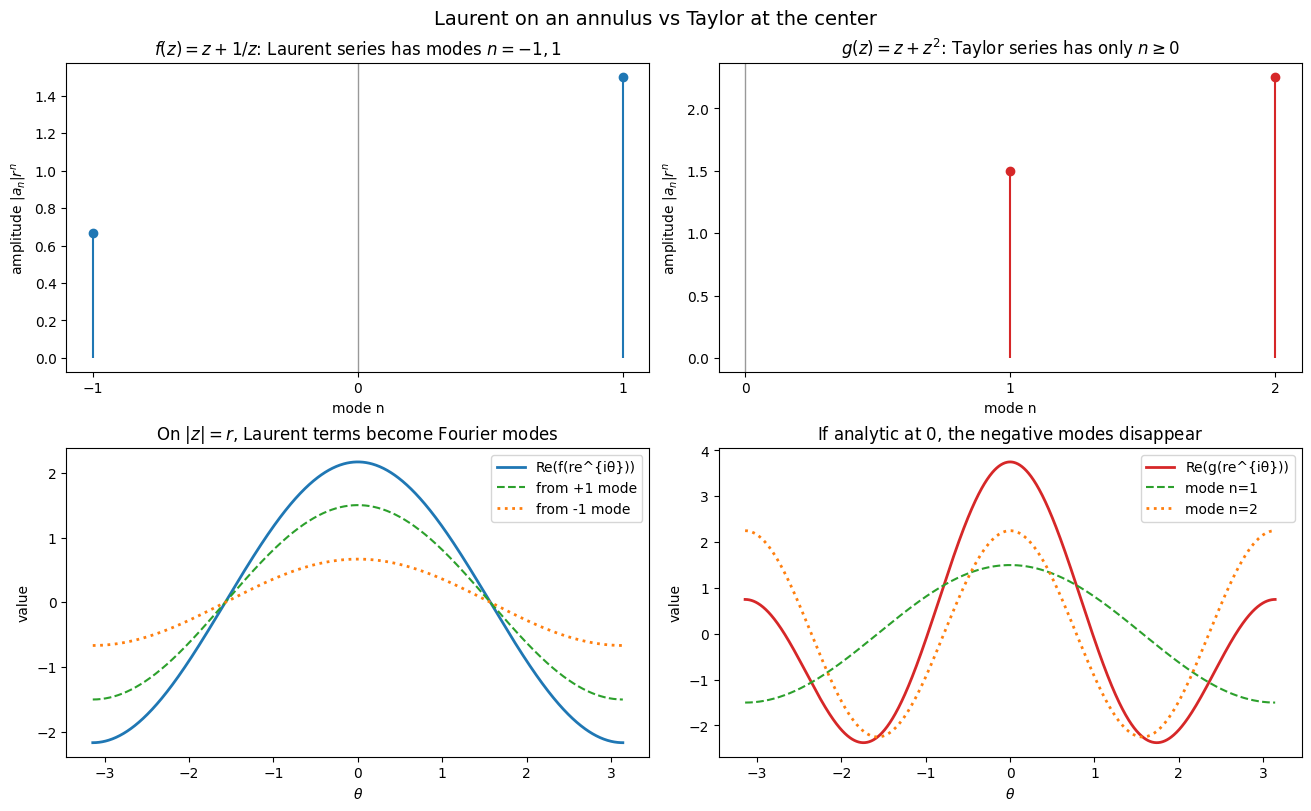

In [2]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(-np.pi, np.pi, 1000)
r = 1.5

# Example 1: Laurent series with a negative mode
f_laurent = r * np.exp(1j * theta) + (1 / r) * np.exp(-1j * theta)   # z + 1/z on |z| = r

# Example 2: Analytic at 0, so only nonnegative modes remain
f_taylor = r * np.exp(1j * theta) + (r**2) * np.exp(2j * theta)       # z + z^2 on |z| = r

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

# Top row: coefficient diagrams as Fourier/Laurent modes
modes_laurent = np.array([-1, 1])
weights_laurent = np.array([1 / r, r])
axes[0, 0].stem(modes_laurent, weights_laurent, basefmt=' ', linefmt='C0-', markerfmt='C0o')
axes[0, 0].axvline(0, color='0.6', lw=1)
axes[0, 0].set_title(r'$f(z)=z+1/z$: Laurent series has modes $n=-1,1$')
axes[0, 0].set_xlabel('mode n')
axes[0, 0].set_ylabel(r'amplitude $|a_n| r^n$')
axes[0, 0].set_xticks([-1, 0, 1])

modes_taylor = np.array([1, 2])
weights_taylor = np.array([r, r**2])
axes[0, 1].stem(modes_taylor, weights_taylor, basefmt=' ', linefmt='C3-', markerfmt='C3o')
axes[0, 1].axvline(0, color='0.6', lw=1)
axes[0, 1].set_title(r'$g(z)=z+z^2$: Taylor series has only $n\geq 0$')
axes[0, 1].set_xlabel('mode n')
axes[0, 1].set_ylabel(r'amplitude $|a_n| r^n$')
axes[0, 1].set_xticks([0, 1, 2])

# Bottom row: restriction to the circle as a function of theta
axes[1, 0].plot(theta, np.real(f_laurent), label='Re(f(re^{iθ}))', color='C0', lw=2)
axes[1, 0].plot(theta, r * np.cos(theta), '--', label='from +1 mode', color='C2')
axes[1, 0].plot(theta, (1 / r) * np.cos(theta), ':', label='from -1 mode', color='C1', lw=2)
axes[1, 0].set_title(r'On $|z|=r$, Laurent terms become Fourier modes')
axes[1, 0].set_xlabel(r'$\theta$')
axes[1, 0].set_ylabel('value')
axes[1, 0].legend()

axes[1, 1].plot(theta, np.real(f_taylor), label='Re(g(re^{iθ}))', color='C3', lw=2)
axes[1, 1].plot(theta, r * np.cos(theta), '--', label='mode n=1', color='C2')
axes[1, 1].plot(theta, (r**2) * np.cos(2 * theta), ':', label='mode n=2', color='C1', lw=2)
axes[1, 1].set_title(r'If analytic at $0$, the negative modes disappear')
axes[1, 1].set_xlabel(r'$\theta$')
axes[1, 1].set_ylabel('value')
axes[1, 1].legend()

plt.suptitle('Laurent on an annulus vs Taylor at the center', fontsize=14)
plt.show()

## Laurent Series as the Master Expansion: Step-by-Step Bridge to Fourier

### Step 1 — The Laurent series lives in the $z$-plane

The Laurent series of $f(z) = z + z^2$ around $0$ is

$$
f(z) = \sum_{n=-\infty}^{\infty} a_n z^n
$$

where in this case $a_1 = 1$, $a_2 = 1$, and all other $a_n = 0$. This is a statement purely about the complex variable $z$ — no angles, no circles yet.

### Step 2 — Choose a circle and parameterize it

Pick any radius $r$ and write every point on the circle $|z| = r$ as

$$
z = r e^{i\theta}, \qquad \theta \in (-\pi, \pi].
$$

This is just polar coordinates restricted to that circle.

### Step 3 — Substitute into the Laurent series

Every term $a_n z^n$ becomes

$$
a_n z^n = a_n (r e^{i\theta})^n = a_n r^n \, e^{in\theta}.
$$

So the full Laurent series becomes

$$
f(re^{i\theta}) = \sum_{n=-\infty}^{\infty} \underbrace{a_n r^n}_{c_n(r)} e^{in\theta}.
$$

This is exactly a Fourier series in $\theta$, with Fourier coefficients $c_n(r) = a_n r^n$.

### Step 4 — Fill in the numbers for $f(z) = z + z^2$

$$
f(re^{i\theta}) = \underbrace{1 \cdot r^1}_{c_1(r)} e^{i\theta} + \underbrace{1 \cdot r^2}_{c_2(r)} e^{2i\theta}.
$$

| Laurent coefficient | Mode $n$ | Fourier amplitude on $\|z\|=r$ |
|---|---|---|
| $a_1 = 1$ | $1$ | $c_1(r) = r$ |
| $a_2 = 1$ | $2$ | $c_2(r) = r^2$ |

### Key insight

The Laurent series is the **master** expansion because:

- The $a_n$'s are fixed by the function alone.
- Choosing a circle $|z| = r$ just sets the scale factor $r^n$ on each mode.
- The Fourier mode structure (which $n$'s appear) never changes with $r$.
- Only the amplitudes $a_n r^n$ change.

Changing $r$ gives a different Fourier series of a different $\theta$-function $F_r(\theta) := f(re^{i\theta})$, but they all descend from the same Laurent table $\{a_n\}$.

## Why Negative Powers Force an Annulus (a Ring)

The answer is purely about **where each type of term stays bounded**.

### Positive powers only (Taylor / disk)

A term $a_n z^n$ with $n \geq 0$ has amplitude

$$
|a_n z^n| = |a_n| \, r^n.
$$

As $r \to 0$, this goes to $0$. It only blows up as $r \to \infty$. So a series of positive powers converges inside a disk

$$
|z| < R_{\text{outer}}.
$$

### Negative powers (Laurent)

A term $a_{-m} z^{-m}$ with $m > 0$ has amplitude

$$
|a_{-m} z^{-m}| = |a_{-m}| \, r^{-m}.
$$

As $r \to 0$, this **blows up** ($r^{-m} \to \infty$). It only becomes small when $r$ is large enough. So a series of negative powers converges **outside** a circle

$$
|z| > r_{\text{inner}}.
$$

### Both together — the annulus

When you combine positive and negative powers in a Laurent series, you need:

- $r < R_{\text{outer}}$ so the positive powers don't blow up,
- $r > r_{\text{inner}}$ so the negative powers don't blow up.

The region where **both** conditions hold simultaneously is exactly an annulus:

$$
r_{\text{inner}} < |z| < R_{\text{outer}}.
$$

### Concrete example: $f(z) = z + \tfrac{1}{z}$

- The $z$ term has amplitude $r$ on $|z|=r$. Fine everywhere except $r \to \infty$.
- The $1/z$ term has amplitude $1/r$ on $|z|=r$. Blows up as $r \to 0$.

So the function only makes sense on the punctured plane $0 < |z| < \infty$, which is an annulus with $r_{\text{inner}}=0^+$ and $R_{\text{outer}}=\infty$.

The inner circle is the **exclusion** forced by the singularity at $z=0$.

On any circle $|z|=r$ inside the annulus, the term $\tfrac{1}{z} = r^{-1} e^{-i\theta}$ contributes the negative Fourier mode $e^{-i\theta}$, which is not present in a Taylor/disk expansion.

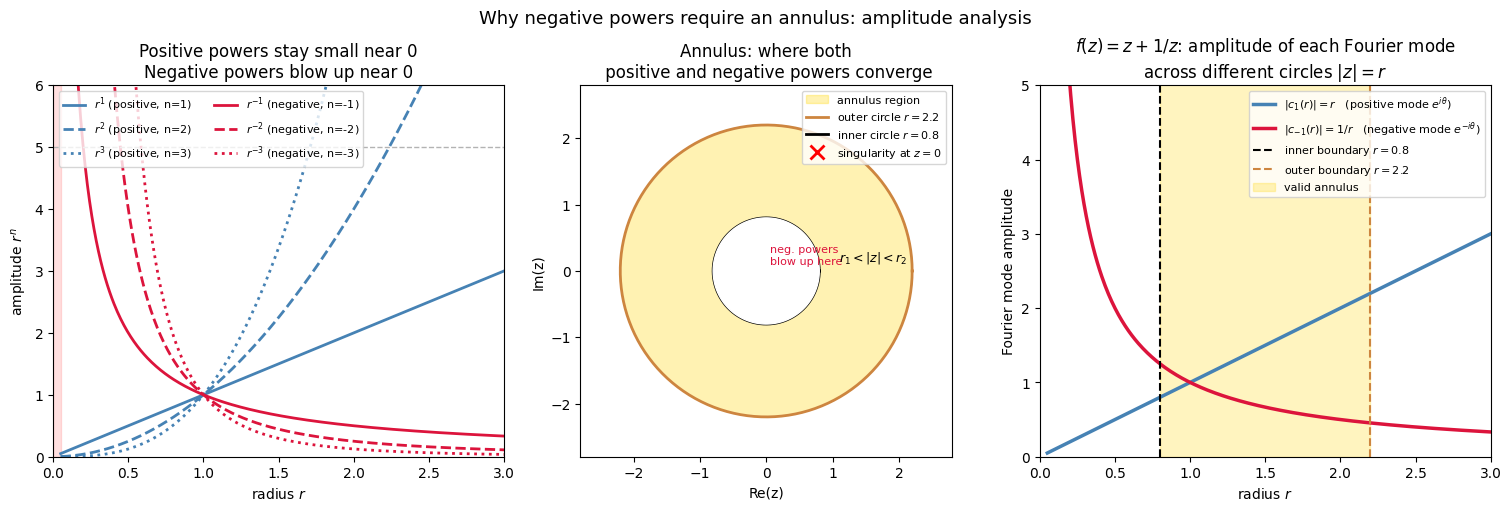

In [4]:
import numpy as np
import matplotlib.pyplot as plt

r_vals = np.linspace(0.05, 3.0, 400)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

# ── Left: amplitude of r^n for various n ──────────────────────────────────────
ax = axes[0]
for n, style in [(1, '-'), (2, '--'), (3, ':')]:
    ax.plot(r_vals, r_vals**n,  label=f'$r^{{{n}}}$ (positive, n={n})', lw=2, ls=style, color='steelblue')
for m, style in [(1, '-'), (2, '--'), (3, ':')]:
    ax.plot(r_vals, r_vals**(-m), label=f'$r^{{-{m}}}$ (negative, n=-{m})', lw=2, ls=style, color='crimson')
ax.axhline(5, color='0.7', lw=1, ls='--')
ax.set_ylim(0, 6)
ax.set_xlim(0, 3)
ax.set_xlabel('radius $r$')
ax.set_ylabel('amplitude $r^n$')
ax.set_title('Positive powers stay small near 0\nNegative powers blow up near 0')
ax.legend(fontsize=8, ncol=2)
ax.fill_betweenx([0, 6], 0, 0.05, color='red', alpha=0.12, label='danger zone for neg. powers')

# ── Middle: convergence regions on the complex plane ─────────────────────────
theta_c = np.linspace(0, 2*np.pi, 400)
ax = axes[1]
r_in, r_out = 0.8, 2.2

# annulus fill
ax.fill(r_out*np.cos(theta_c), r_out*np.sin(theta_c), color='gold', alpha=0.3, label='annulus region')
ax.fill(r_in*np.cos(theta_c),  r_in*np.sin(theta_c),  color='white', zorder=3)
ax.plot(r_out*np.cos(theta_c), r_out*np.sin(theta_c), 'peru', lw=2, label=f'outer circle $r={r_out}$')
ax.plot(r_in*np.cos(theta_c),  r_in*np.sin(theta_c),  'k',   lw=2, label=f'inner circle $r={r_in}$')
ax.plot(0, 0, 'rx', ms=10, mew=2, label='singularity at $z=0$')
ax.set_aspect('equal')
ax.set_xlim(-2.8, 2.8); ax.set_ylim(-2.8, 2.8)
ax.set_xlabel('Re(z)'); ax.set_ylabel('Im(z)')
ax.set_title('Annulus: where both\n positive and negative powers converge')
ax.legend(fontsize=8, loc='upper right')
ax.text(0.05, 0.1, 'neg. powers\nblow up here', fontsize=8, color='crimson')
ax.text(1.1, 0.15, r'$r_1<|z|<r_2$', fontsize=9)

# ── Right: amplitude of each mode of f(z) = z + 1/z on circles ──────────────
ax = axes[2]
ax.plot(r_vals, r_vals,      label=r'$|c_1(r)| = r$   (positive mode $e^{i\theta}$)',  color='steelblue', lw=2.5)
ax.plot(r_vals, 1/r_vals,    label=r'$|c_{-1}(r)| = 1/r$   (negative mode $e^{-i\theta}$)', color='crimson',   lw=2.5)
ax.axvline(r_in,  color='k',    lw=1.5, ls='--', label=f'inner boundary $r={r_in}$')
ax.axvline(r_out, color='peru', lw=1.5, ls='--', label=f'outer boundary $r={r_out}$')
ax.fill_betweenx([0, 6], r_in, r_out, color='gold', alpha=0.25, label='valid annulus')
ax.set_xlim(0, 3); ax.set_ylim(0, 5)
ax.set_xlabel('radius $r$')
ax.set_ylabel('Fourier mode amplitude')
ax.set_title(r'$f(z)=z+1/z$: amplitude of each Fourier mode' + '\n' + r'across different circles $|z|=r$')
ax.legend(fontsize=8)

plt.suptitle('Why negative powers require an annulus: amplitude analysis', fontsize=13)
plt.show()

## Residues in Polar Coordinates — Why Only the $n=-1$ Term Survives

Near a pole at $z_0$, write $z - z_0 = \varepsilon e^{i\phi}$, so

$$
dz = i\varepsilon e^{i\phi}\, d\phi.
$$

Integrating a general Laurent term around a small circle of radius $\varepsilon$:

$$
\oint a_n (z-z_0)^n\, dz
= a_n \int_0^{2\pi} \varepsilon^n e^{in\phi} \cdot i\varepsilon e^{i\phi}\, d\phi
= a_n\, i\, \varepsilon^{n+1} \int_0^{2\pi} e^{i(n+1)\phi}\, d\phi.
$$

Now use Fourier orthogonality of $e^{ik\phi}$ on $[0, 2\pi]$:

$$
\int_0^{2\pi} e^{ik\phi}\, d\phi = \begin{cases} 2\pi & k = 0 \\ 0 & k \neq 0 \end{cases}
$$

So the integral is nonzero **only** when $n + 1 = 0$, i.e. $n = -1$:

$$
\oint a_{-1} (z-z_0)^{-1}\, dz = a_{-1}\, i\, \varepsilon^{0} \cdot 2\pi = 2\pi i\, a_{-1}.
$$

The $\varepsilon$ from $dz$ exactly cancels the $1/\varepsilon$ from the pole, giving a result **independent of the circle radius**.

This is the residue theorem:

$$
\boxed{\oint_C f(z)\, dz = 2\pi i \sum_{\text{poles inside } C} \operatorname{Res}[f, z_k]}
$$

The residue is not just a coefficient — it is the **unique resonance** between the $z^{-1}$ singularity and the circular measure $dz = i\varepsilon e^{i\phi} d\phi$. Every other mode either vanishes by Fourier orthogonality ($n \neq -1$), or scales with $\varepsilon^{n+1} \to 0$ as the circle shrinks.

## Geometric Meaning of Each Mode $e^{in\theta}$

On the unit circle $z = e^{i\theta}$, the Laurent series becomes the Fourier series:

$$
f(e^{i\theta}) = \sum_{n=-\infty}^{\infty} c_n \, e^{in\theta}
$$

Each mode $e^{in\theta}$ is a **point rotating on the unit circle at integer angular frequency $n$**.

---

### The three cases

| $n$ | Geometry |
|-----|----------|
| $n > 0$ | Rotates **counterclockwise**, completing $n$ full laps as $\theta: 0 \to 2\pi$ |
| $n = 0$ | Constant — no rotation (DC offset) |
| $n < 0$ | Rotates **clockwise**, completing $|n|$ full laps |

---

### Epicycle / phasor picture

Each term $c_n e^{in\theta}$ is a **rotating vector (phasor)**:

- **Radius**: $|c_n|$ — how much this mode contributes  
- **Initial angle**: $\arg(c_n)$ — its phase offset  
- **Rotation rate**: $n$ (counterclockwise if positive, clockwise if negative)

The full sum stacks these rotating arms tip-to-tail. Their combined tip traces the curve $f(e^{i\theta})$. This is precisely **Ptolemy's epicycle construction** — any closed curve in $\mathbb{C}$ can be drawn by a superposition of circles spinning at integer rates.

---

### Why both $\pm n$ appear (vs. real Fourier)

In real Fourier analysis you need $\cos(n\theta)$ and $\sin(n\theta)$ because real functions have no preferred handedness. In the complex Laurent picture:

$$
\cos(n\theta) = \frac{e^{in\theta} + e^{-in\theta}}{2}
$$

The $+n$ and $-n$ modes are **mirror rotations** — one CCW, one CW — that combine to produce purely real oscillations. A function analytic inside the disk has only $n \geq 0$ modes (Taylor series); poles introduce $n < 0$ modes (winding around singularities).

---

### Winding number connection

$e^{in\theta}$ has **winding number $n$** around the origin. The Laurent coefficient

$$
c_n = \frac{1}{2\pi i} \oint \frac{f(z)}{z^{n+1}} \, dz
$$

counts how the function "wraps" at each rotational frequency. This is why the $n = -1$ coefficient (the residue) is special: it captures the $2\pi i$ single winding that Cauchy's theorem measures — as shown in the residue calculation above.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2 * np.pi, 500)

modes = [-2, -1, 0, 1, 2, 3]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for ax, n in zip(axes, modes):
    z = np.exp(1j * n * theta)
    ax.plot(z.real, z.imag, lw=2)
    # Mark start and a quarter-turn to show rotation direction
    ax.annotate("", xy=(z.real[125], z.imag[125]), xytext=(z.real[0], z.imag[0]),
                arrowprops=dict(arrowstyle="->", color="red", lw=1.5))
    ax.set_aspect("equal")
    ax.set_title(f"$e^{{i({n})\\theta}}$,  $n={n}$", fontsize=13)
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(0, color="k", lw=0.5)
    ax.grid(True, alpha=0.3)
    direction = "CCW" if n > 0 else ("CW" if n < 0 else "constant")
    ax.set_title(f"$n={n}$  ({direction}, {abs(n)} lap{'s' if abs(n)!=1 else ''})", fontsize=11)

fig.suptitle("Fourier/Laurent modes $e^{in\\theta}$ on the unit circle", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## Why $\int_0^{2\pi} e^{in\theta}\, d\theta = 0$ for $n \neq 0$ — the Symmetry Argument

$$
\int_0^{2\pi} e^{in\theta}\, d\theta = 0, \quad n \neq 0
$$

**Geometric intuition:** $e^{in\theta}$ traces the unit circle $|n|$ times as $\theta$ sweeps $[0, 2\pi)$. The integral sums all those unit vectors. By the **rotational symmetry of the circle**, for every vector pointing in one direction there is an equal vector pointing the opposite way — they cancel in pairs. The sum of all equally-spaced unit vectors on a circle is always zero.

---

### Symmetry argument (rigorous)

Shift the integration variable $\theta \mapsto \theta + \alpha$ for any fixed $\alpha$. The circle is unchanged by rotation, so the integral $I$ is the same:

$$
I = \int_0^{2\pi} e^{in(\theta + \alpha)}\, d\theta = e^{in\alpha} \int_0^{2\pi} e^{in\theta}\, d\theta = e^{in\alpha}\, I
$$

Rearranging:

$$
\left(e^{in\alpha} - 1\right) I = 0
$$

For $n \neq 0$, choose $\alpha = \pi/n$ so that $e^{in\alpha} = e^{i\pi} = -1 \neq 1$. This forces:

$$
\boxed{I = 0}
$$

For $n = 0$: $e^{i \cdot 0 \cdot \alpha} = 1$ for all $\alpha$, so the argument gives no information — and indeed $\int_0^{2\pi} 1\, d\theta = 2\pi$.

---

### Why this matters for the residue theorem

This is the exact same cancellation that kills every Laurent mode except $n = -1$ in the contour integral:

$$
\oint a_n (z - z_0)^n\, dz = a_n \, i \, \varepsilon^{n+1} \underbrace{\int_0^{2\pi} e^{i(n+1)\phi}\, d\phi}_{2\pi \text{ if } n=-1,\ 0 \text{ otherwise}}
$$

The $n = 0$ mode of the **substituted** integral corresponds to $n = -1$ in the Laurent series — the residue is the unique mode that the rotational symmetry cannot kill.

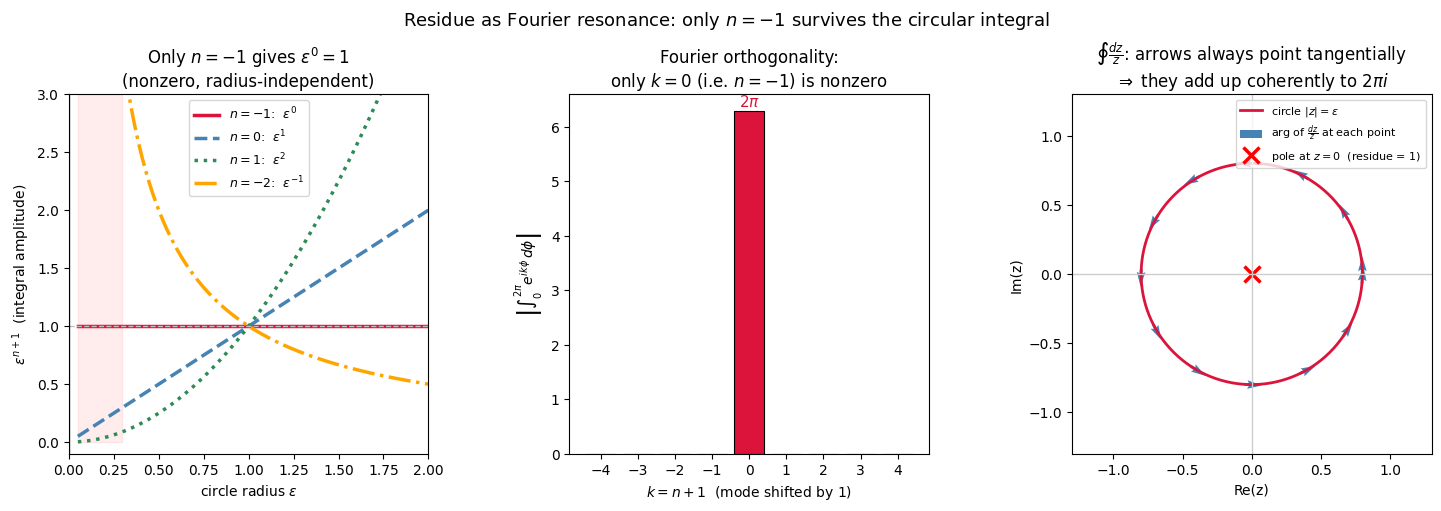

In [6]:
import numpy as np
import matplotlib.pyplot as plt

eps_vals = np.linspace(0.05, 2.0, 300)
phi = np.linspace(0, 2 * np.pi, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

# ── Left: eps^(n+1) vs eps for various n — which modes survive as eps -> 0 ───
ax = axes[0]
for n, color, ls in [(-1, 'crimson', '-'), (0, 'steelblue', '--'),
                      (1, 'seagreen', ':'), (-2, 'orange', '-.')]:
    power = n + 1
    label = fr'$n={n}$:  $\varepsilon^{{{power}}}$'
    ax.plot(eps_vals, eps_vals**power, color=color, ls=ls, lw=2.5, label=label)
ax.axhline(1, color='0.75', lw=1, ls='--')
ax.axvline(0, color='0.4', lw=1)
ax.set_ylim(-0.1, 3)
ax.set_xlim(0, 2)
ax.set_xlabel(r'circle radius $\varepsilon$')
ax.set_ylabel(r'$\varepsilon^{n+1}$  (integral amplitude)')
ax.set_title('Only $n=-1$ gives $\\varepsilon^0 = 1$\n(nonzero, radius-independent)')
ax.legend(fontsize=9)
ax.fill_between(eps_vals, 0, 3, where=(eps_vals < 0.3),
                color='red', alpha=0.07, label='as circle shrinks')
ax.set_box_aspect(1)

# ── Middle: Fourier orthogonality — angular integral of e^{i k phi} ──────────
ax = axes[1]
ks = np.arange(-4, 5)
integrals = np.array([np.abs(np.trapezoid(np.exp(1j * k * phi), phi)) for k in ks])
bars = ax.bar(ks, integrals, color=['crimson' if k == 0 else 'steelblue' for k in ks],
              edgecolor='k', linewidth=0.8)
ax.set_xlabel('$k = n+1$  (mode shifted by 1)')
ax.set_ylabel(r'$\left|\int_0^{2\pi} e^{ik\phi}\,d\phi\right|$')
ax.set_title('Fourier orthogonality:\nonly $k=0$ (i.e. $n=-1$) is nonzero')
ax.set_xticks(ks)
ax.text(0, integrals[ks == 0][0] + 0.1, r'$2\pi$', ha='center', fontsize=11, color='crimson')
ax.set_box_aspect(1)

# ── Right: the contour integral visually for f(z) = 1/z around z=0 ──────────
ax = axes[2]
eps = 0.8
z_circle = eps * np.exp(1j * phi)
# Contributions to integrand 1/z * dz = i dphi  =>  all equal magnitude, direction rotates
contrib_angle = phi + np.pi / 2            # arg of i * e^{i*phi} * e^{-i*phi} = i
x_c = eps * np.cos(phi)
y_c = eps * np.sin(phi)
ax.plot(x_c, y_c, 'crimson', lw=2, label=r'circle $|z|=\varepsilon$')
# Draw a few integrand direction arrows
step = len(phi) // 12
ax.quiver(x_c[::step], y_c[::step],
          np.cos(contrib_angle[::step]), np.sin(contrib_angle[::step]),
          angles='xy', scale_units='xy', scale=8, color='steelblue',
          width=0.008, label=r'arg of $\frac{dz}{z}$ at each point')
ax.plot(0, 0, 'rx', ms=12, mew=2.5, label='pole at $z=0$  (residue = 1)')
ax.set_aspect('equal')
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.axhline(0, color='0.8', lw=1); ax.axvline(0, color='0.8', lw=1)
ax.set_xlabel('Re(z)'); ax.set_ylabel('Im(z)')
ax.set_title(r'$\oint \frac{dz}{z}$: arrows always point tangentially' +
             '\n' + r'$\Rightarrow$ they add up coherently to $2\pi i$')
ax.legend(fontsize=8, loc='upper right')

plt.suptitle(r'Residue as Fourier resonance: only $n=-1$ survives the circular integral', fontsize=13)
plt.show()

## Laurent Coefficients — Derivatives vs. Contour Integrals

### Taylor coefficients — derivatives

For a function analytic at $z_0$, the Taylor series is:

$$
f(z) = \sum_{n=0}^{\infty} a_n (z - z_0)^n, \qquad a_n = \frac{f^{(n)}(z_0)}{n!}
$$

Derivatives extract coefficients by differentiating away all other terms.

---

### Laurent coefficients — contour integrals

For an annular region around $z_0$, the Laurent series is:

$$
f(z) = \sum_{n=-\infty}^{\infty} a_n (z - z_0)^n
$$

To isolate $a_k$, multiply both sides by $(z - z_0)^{-(k+1)}$ and integrate around a circle:

$$
\oint_C \frac{f(z)}{(z-z_0)^{k+1}}\, dz = \sum_{n=-\infty}^{\infty} a_n \oint_C (z-z_0)^{n-k-1}\, dz
$$

By the rotational symmetry argument, every term on the right is zero **except** $n = k$, where $n - k - 1 = -1$:

$$
\oint_C \frac{f(z)}{(z-z_0)^{k+1}}\, dz = a_k \cdot 2\pi i
$$

So:

$$
\boxed{a_k = \frac{1}{2\pi i} \oint_C \frac{f(z)}{(z-z_0)^{k+1}}\, dz}
$$

---

### They are the same for $n \geq 0$

For non-negative $n$, the contour integral formula **is** Cauchy's differentiation formula:

$$
\frac{1}{2\pi i} \oint_C \frac{f(z)}{(z-z_0)^{n+1}}\, dz = \frac{f^{(n)}(z_0)}{n!}
$$

So $a_n = f^{(n)}(z_0)/n!$ — the same Taylor coefficient. The contour integral computes the derivative non-locally.

---

### Where they differ: $n < 0$

For negative $n$, $f^{(n)}$ has no meaning (you cannot differentiate $-2$ times). The contour integral formula **extends** the idea to negative indices — it is the only way to define $a_{-1}, a_{-2}, \ldots$ — and those terms capture the singular behaviour near the pole that derivatives cannot see.

The hierarchy is:

$$
\text{derivatives} \;\subset\; \text{Cauchy's formula} \;=\; \text{Laurent coefficients for all } n \in \mathbb{Z}
$$

## Laurent Series → Fourier Series → Fourier Transform → Laplace Transform

### 1. Laurent Series (discrete modes, complex plane)

For $f(z)$ analytic in an annulus $r_1 < |z| < r_2$:

$$f(z) = \sum_{n=-\infty}^{\infty} c_n \, z^n, \qquad c_n = \frac{1}{2\pi i} \oint_\gamma \frac{f(z)}{z^{n+1}} \, dz$$

The modes $n$ are **integers** — the Laurent series is inherently discrete in frequency.

---

### 2. Restrict to the Unit Circle → Fourier Series

Set $z = e^{i\theta}$, $\theta \in [0, 2\pi)$. Then $z^n = e^{in\theta}$ and:

$$f(e^{i\theta}) = \sum_{n=-\infty}^{\infty} c_n \, e^{in\theta}$$

The Laurent contour integral on $|z|=1$ becomes:

$$c_n = \frac{1}{2\pi i} \oint \frac{f(z)}{z^{n+1}} dz \;\xrightarrow{z=e^{i\theta}}\; c_n = \frac{1}{2\pi} \int_0^{2\pi} f(e^{i\theta}) \, e^{-in\theta} \, d\theta$$

**This is exactly the Fourier series.** The Laurent coefficients $c_n$ are the Fourier coefficients. The unit circle is the fundamental domain.

---

### 3. Let the Period → ∞ → Fourier Transform

The Fourier series assumes $f$ is periodic with period $2\pi$. Take the period $T \to \infty$: the discrete sum over integer modes $n$ becomes a **continuous integral** over frequency $\omega \in \mathbb{R}$:

$$\sum_{n} c_n \, e^{in\theta} \;\xrightarrow{T\to\infty}\; \int_{-\infty}^{\infty} \hat{f}(\omega) \, e^{i\omega \theta} \, d\omega$$

$$\hat{f}(\omega) = \int_{-\infty}^{\infty} f(\theta) \, e^{-i\omega \theta} \, d\theta$$

The **mode index $n$ becomes continuous frequency $\omega$**. The Fourier transform is the Laurent series restricted to the imaginary axis $s = i\omega$ of the complex plane.

---

### 4. Move Off the Unit Circle → Laplace Transform / Z-Transform

The Laurent series converges in an **annulus** $r_1 < |z| < r_2$. Moving $z$ off the unit circle adds a radial component. Set $z = e^{sT}$ where $s = \sigma + i\omega$:

$$\mathcal{Z}\{x[n]\} = \sum_{n=-\infty}^{\infty} x[n]\, z^{-n}$$

This is a **Laurent series in $z$**. Its region of convergence (ROC) is an annulus, which maps to a vertical strip $\sigma_1 < \operatorname{Re}(s) < \sigma_2$ in the $s$-plane.

Taking $T \to 0$ (continuous-time limit) gives the **Laplace transform**:

$$\mathcal{L}\{f\}(s) = \int_0^\infty f(t)\, e^{-st}\, dt, \quad s = \sigma + i\omega$$

The factor $e^{-\sigma t}$ is a **convergence damping term** that allows transforms of functions (like $e^t$) whose pure Fourier transform diverges. The Fourier transform is the Laplace transform restricted to the imaginary axis $\sigma = 0$.

---

### Full Correspondence Table

| Tool | Variable | Modes | Domain | Convergence region |
|---|---|---|---|---|
| Laurent series | $z$ (complex) | discrete $n \in \mathbb{Z}$ | annulus | $r_1 < \|z\| < r_2$ |
| Fourier series | $z = e^{i\theta}$ | discrete $n \in \mathbb{Z}$ | unit circle | periodic $f$ |
| Fourier transform | $\omega \in \mathbb{R}$ | continuous $\omega$ | imaginary axis | $L^2$ functions |
| Z-transform | $z = e^{sT}$ | discrete $n \in \mathbb{Z}$ | annulus | strip in $s$-plane |
| Laplace transform | $s = \sigma+i\omega$ | continuous $\omega$ | right half-plane | $\operatorname{Re}(s) > \sigma_0$ |

**Unifying idea**: all of these expand a function in complex exponentials $e^{in\theta}$ or $e^{st}$. The Laurent series is the algebraic backbone; restricting to the unit circle yields Fourier; analytic continuation off it yields Laplace/Z. The modes go from discrete integers $n$ → continuous $\omega$ as the period $T \to \infty$.
